# HW3 - Time Series Classification (AReM)
DSCI 552

Name: Ruikun Zhang
GitHub Username: XOBECIUJ
USC ID:

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score, ConfusionMatrixDisplay, RocCurveDisplay

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# Problem 1: Feature Creation / Extraction

## (a) Download the data

The AReM data is stored in `../data/AReM`, with one folder per activity.

In [2]:
def load(path):
    lines = [l for l in open(path) if l.strip() and not l.startswith('#')]
    return np.array([l.replace(',', ' ').split() for l in lines], dtype=float)[:, 1:]

folders = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
instances = []
for f in folders:
    for i in range(1, 16):
        path = f'../data/AReM/{f}/dataset{i}.csv'
        if os.path.exists(path):
            instances.append((f, i, load(path)))

print('instances:', len(instances))
print('shapes other than (480, 6):', [(f, i, a.shape) for f, i, a in instances if a.shape != (480, 6)])

instances: 88
shapes other than (480, 6): [('sitting', 8, (479, 6))]


There are 88 instances with 6 time series each. All have 480 rows except sitting/dataset8, which has 479 rows; it is used as it is.

## (b) Train and test split

Datasets 1 and 2 in bending1 and bending2, and datasets 1, 2 and 3 in the other folders, are the test data.

In [3]:
is_test = np.array([i <= 2 if f.startswith('bending') else i <= 3 for f, i, a in instances])
y_all = np.array([f.startswith('bending') for f, i, a in instances]).astype(int)
activity = np.array([f for f, i, a in instances])

print('train:', (~is_test).sum(), ' test:', is_test.sum())
print('bending in train:', y_all[~is_test].sum(), ' other in train:', (y_all[~is_test] == 0).sum())

train: 69  test: 19
bending in train: 9  other in train: 60


## (c) Feature extraction

### (i) Time-domain features

Common time-domain features used for time series classification:

- minimum, maximum, range
- mean, median
- standard deviation, variance
- first quartile, third quartile, interquartile range
- skewness, kurtosis
- root mean square
- number of zero crossings or mean crossings
- number of peaks
- mean absolute change between consecutive values

### (ii) Extract the features

In [4]:
stats = ['min', 'max', 'mean', 'median', 'std', 'q1', 'q3']

def extract(a, l=1):
    out = []
    for part in np.array_split(a, l):
        for j in range(6):
            x = part[:, j]
            out += [x.min(), x.max(), x.mean(), np.median(x), x.std(), np.percentile(x, 25), np.percentile(x, 75)]
    return out

def names(l=1):
    if l == 1:
        return [f'{s}_{j}' for j in range(1, 7) for s in stats]
    return [f'{s}_{j}_part{p}' for p in range(1, l + 1) for j in range(1, 7) for s in stats]

features = pd.DataFrame([extract(a) for f, i, a in instances], columns=names(1))
features.index = range(1, 89)
features.head()

,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,min_2,max_2,mean_2,...,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
1,37.25,45.00,40.624792,40.50,1.475428,39.25,42.00,0.0,1.30,0.358604,...,2.186168,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582308,0.0,1.30
2,38.00,45.67,42.812812,42.50,1.434054,42.00,43.67,0.0,1.22,0.372437,...,1.993175,32.0000,34.50,0.0,3.11,0.571083,0.43,0.600383,0.0,1.30
3,35.00,47.40,43.954500,44.33,1.557210,43.00,45.00,0.0,1.70,0.426250,...,1.997520,35.3625,36.50,0.0,1.79,0.493292,0.43,0.512971,0.0,0.94
4,33.00,47.75,42.179812,43.50,3.666840,39.15,45.00,0.0,3.00,0.696042,...,3.845436,30.4575,36.33,0.0,2.18,0.613521,0.50,0.523771,0.0,1.00
5,33.00,45.75,41.678063,41.75,2.241152,41.33,42.75,0.0,2.83,0.535979,...,2.408514,28.4575,31.25,0.0,1.79,0.383292,0.43,0.388759,0.0,0.50


### (iii) Standard deviation and 90% bootstrap confidence interval

In [5]:
rng = np.random.default_rng(0)
B = 1000
boot = np.array([features.iloc[rng.integers(0, 88, 88)].std().values for _ in range(B)])

ci = pd.DataFrame({'std': features.std(), 'lower 5%': np.percentile(boot, 5, axis=0), 'upper 95%': np.percentile(boot, 95, axis=0)})
ci.round(3)

,std,lower 5%,upper 95%
min_1,9.570,8.295,10.819
max_1,4.394,3.335,5.273
mean_1,5.336,4.706,5.851
median_1,5.440,4.841,6.000
std_1,1.770,1.572,1.955
q1_1,6.154,5.615,6.641
q3_1,5.139,4.336,5.841
min_2,0.000,0.000,0.000
max_2,5.063,4.626,5.375
mean_2,1.574,1.394,1.702


### (iv) Three most important features

The three features chosen are the minimum, the mean and the maximum. Together they describe the level and the range of each series, while the median and the quartiles are almost copies of the mean, and the standard deviation mostly repeats the range. The bootstrap intervals above show that these features vary a lot between instances, so they can separate activities. One limitation is that the minimum of the variance series (series 2, 4 and 6) is 0 in almost every instance, so it carries little information for those series.

# Problem 4: Binary and Multiclass Classification

## (a) Binary classification using logistic regression

### (i) Scatter plots of min, mean and max of time series 1, 2 and 6 (training set)

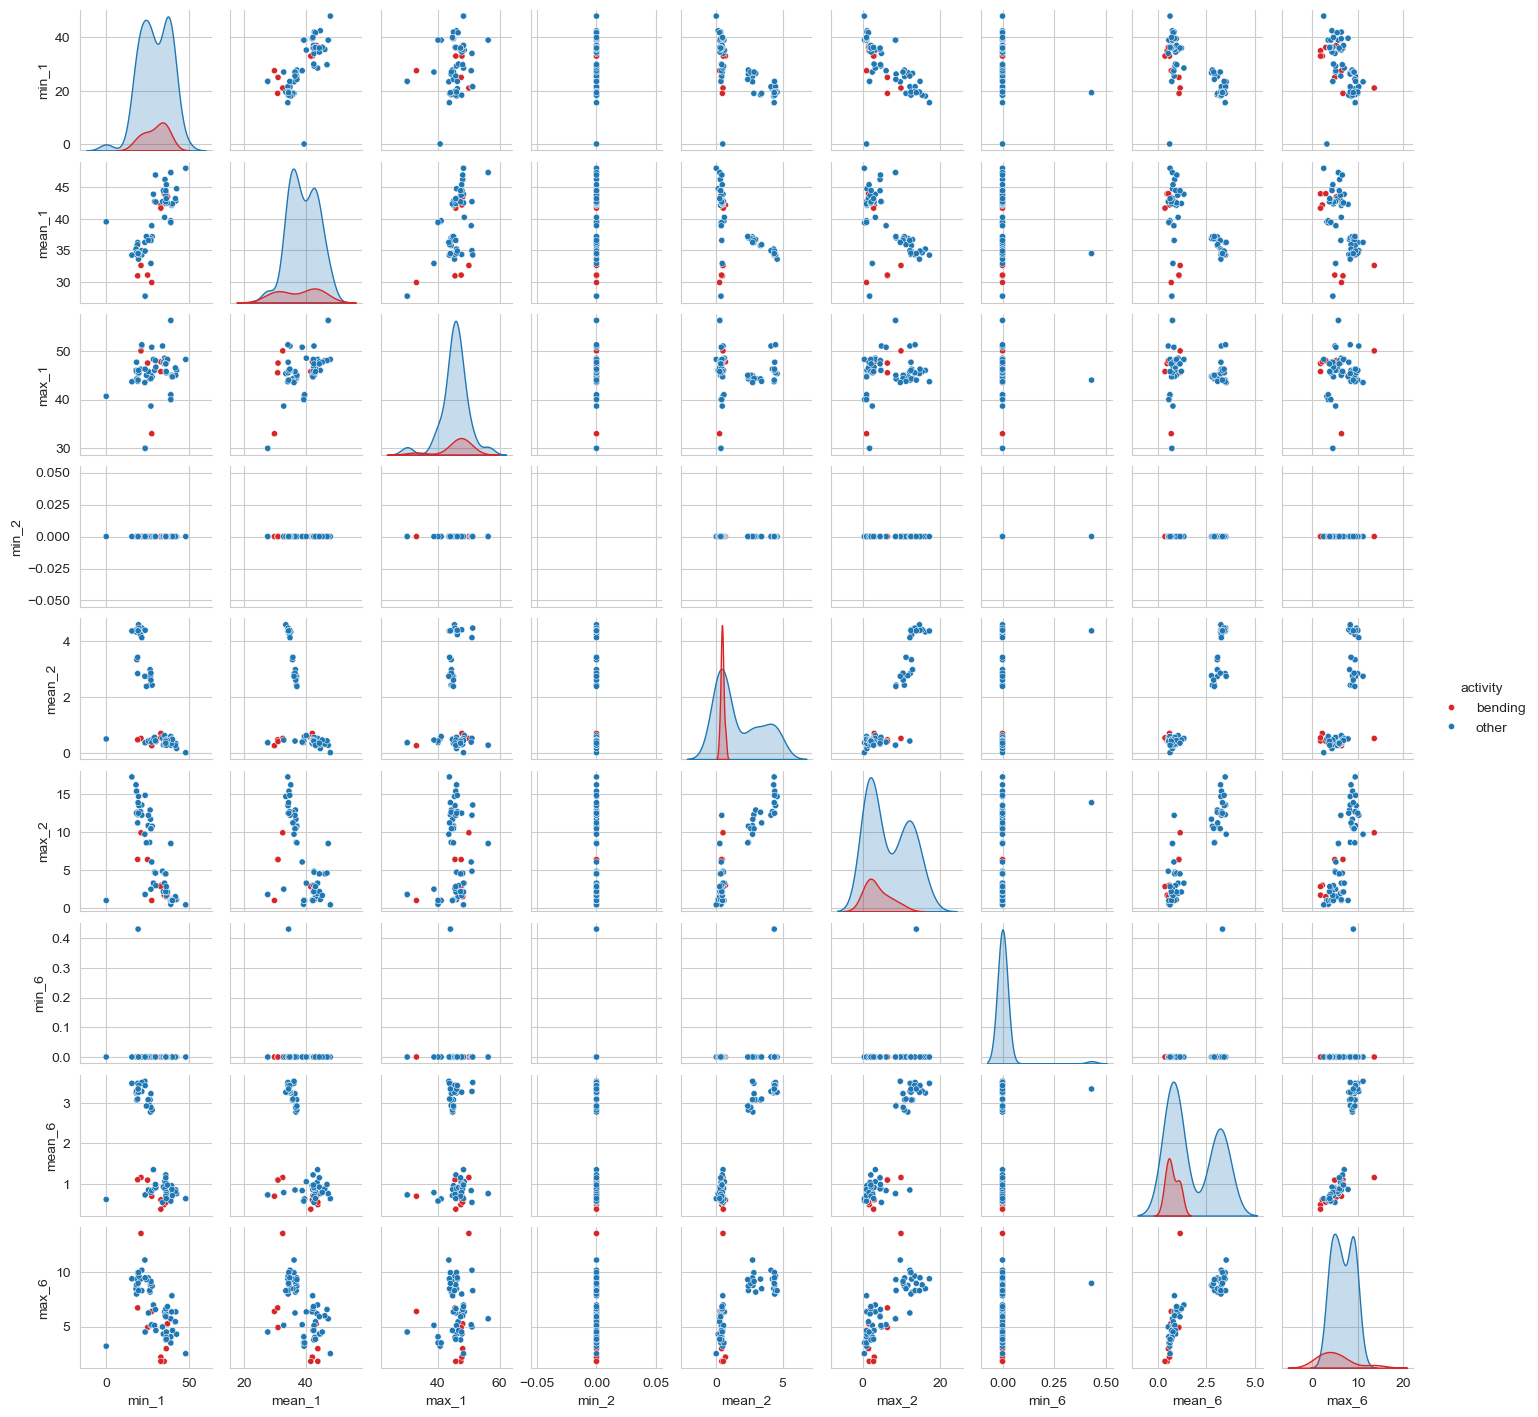

In [6]:
train_idx = np.where(~is_test)[0]
y_train = y_all[train_idx]
label = np.where(y_train == 1, 'bending', 'other')

cols9 = [f'{s}_{j}' for j in [1, 2, 6] for s in ['min', 'mean', 'max']]
X1 = features.iloc[train_idx][cols9].reset_index(drop=True)
X1['activity'] = label
sns.pairplot(X1, hue='activity', palette={'bending': 'tab:red', 'other': 'tab:blue'}, height=1.6, plot_kws={'s': 20})
plt.show()

In the scatter plots the bending instances (red) sit in a small region with a low mean and low max of the variance series (series 2 and 6), whereas cycling and walking have much larger values there. Bending is not separated from every other activity in a single plot, because lying, sitting and standing also have small variance, and the min of series 2 and 6 is 0 for almost all points. The plots that combine a variance feature with a feature of series 1 show the best separation.

### (ii) Break each training series into two parts

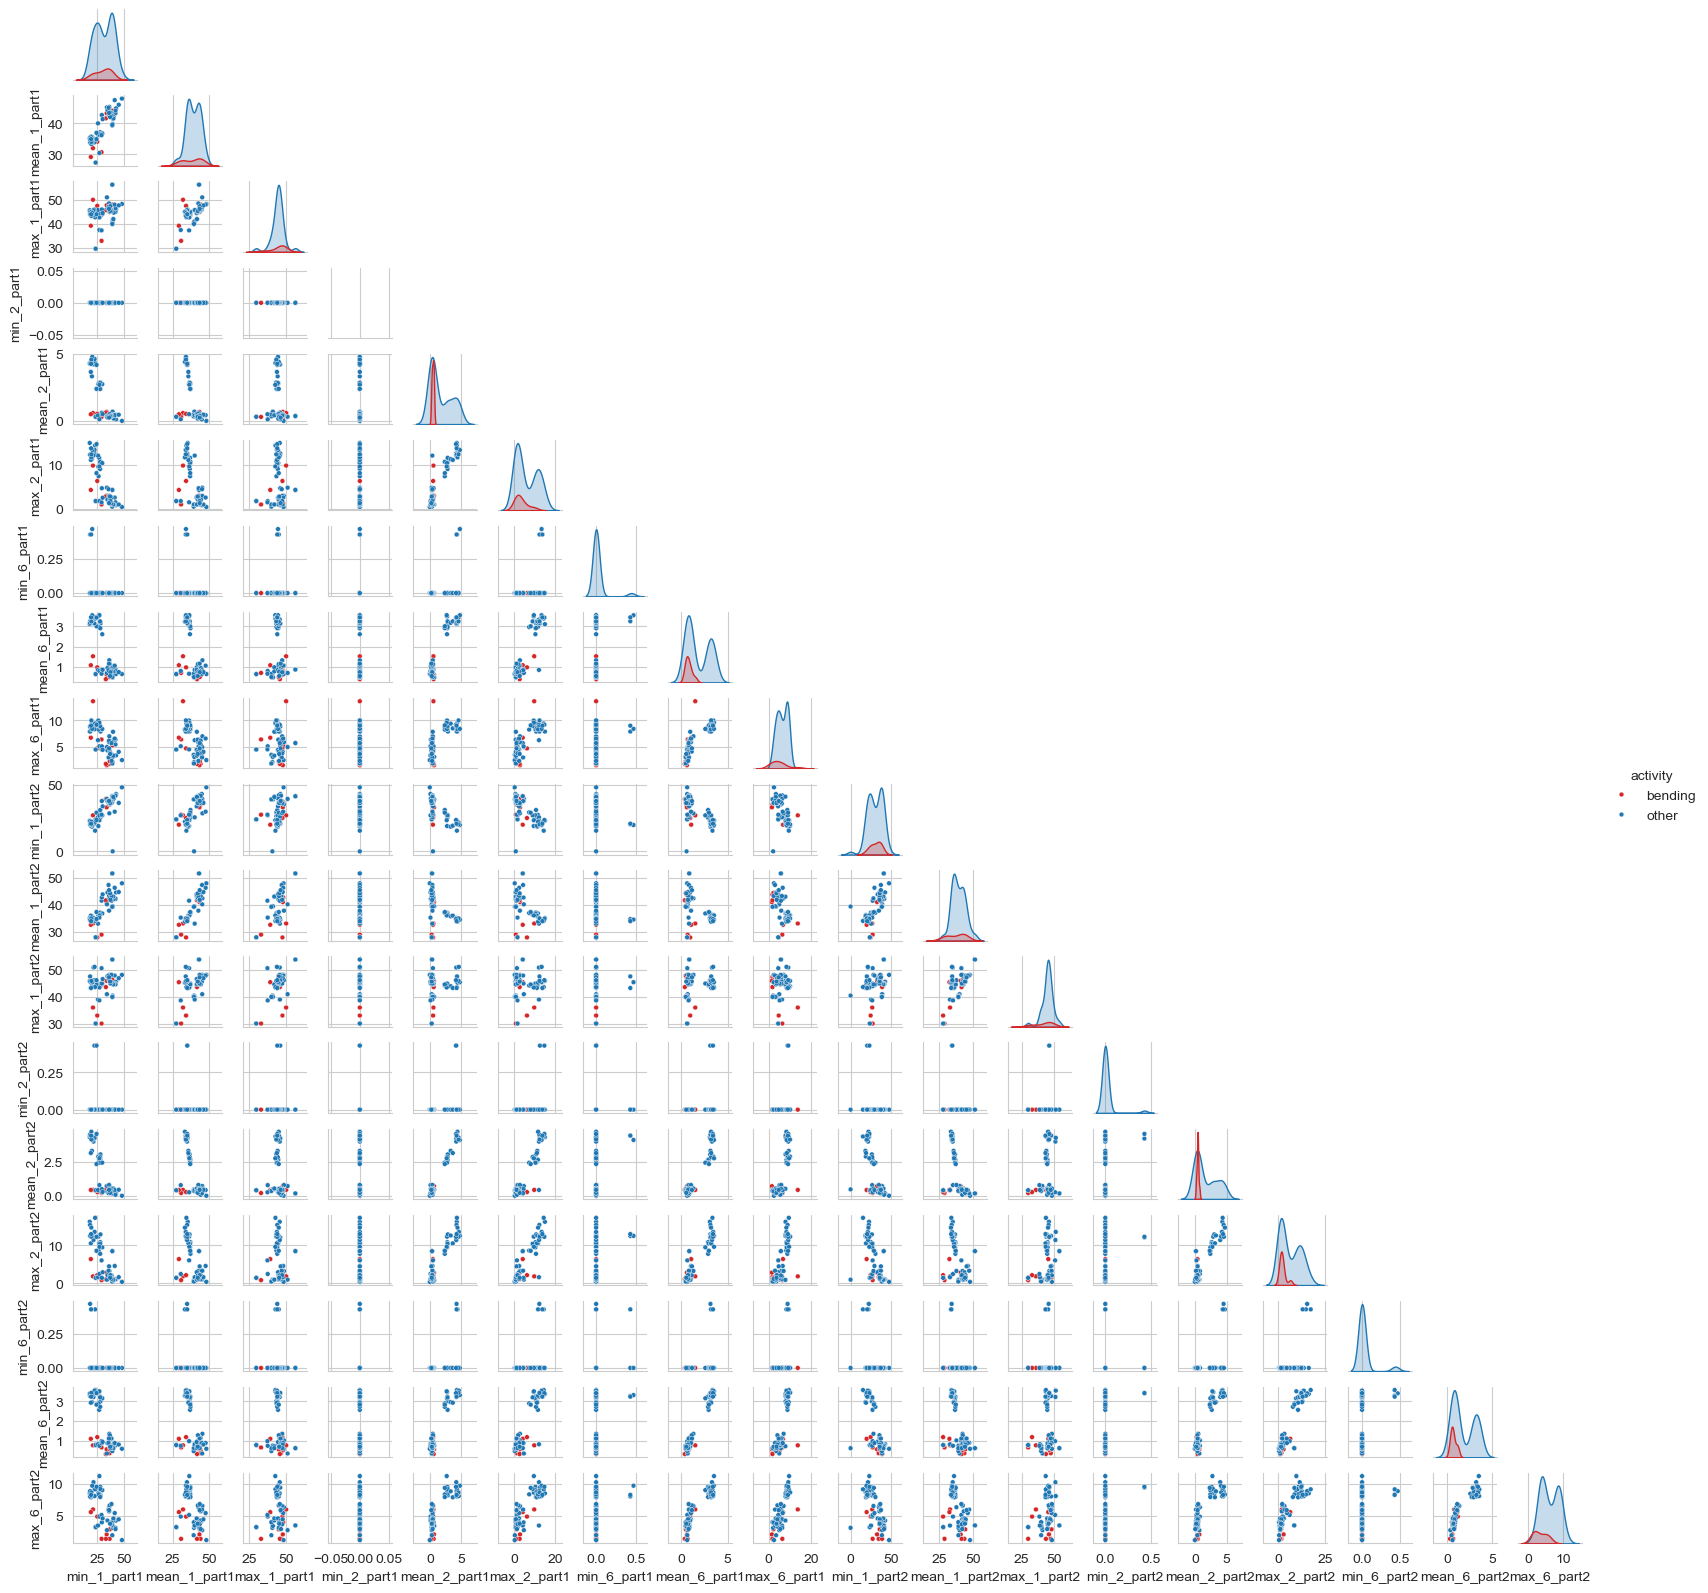

In [7]:
X2_all = pd.DataFrame([extract(a, 2) for f, i, a in instances], columns=names(2))
cols18 = [f'{s}_{j}_part{p}' for p in [1, 2] for j in [1, 2, 6] for s in ['min', 'mean', 'max']]
X2 = X2_all.iloc[train_idx][cols18].reset_index(drop=True)
X2['activity'] = label
sns.pairplot(X2, hue='activity', palette={'bending': 'tab:red', 'other': 'tab:blue'}, height=0.9, plot_kws={'s': 12}, corner=True)
plt.show()

Splitting each series into two parts gives 18 features and the plots look similar to the ones in (i). The bending points remain in the low-variance region and mix with the other still activities in many panels. The two halves of the same feature are strongly related to each other, so most of the new panels do not add much separation. There is no considerable difference from 4(a)i.

### (iii) Choose (l, p) with 5-fold cross-validation

Each series is split into l pieces (l = 1, ..., 20) and the same 7 time-domain features are taken from each piece, so every instance has 42 * l features. Recursive feature elimination (RFE) with an unpenalized logistic regression is used for backward selection, and p is the number of features kept.

Right way to cross-validate: feature selection (and scaling) must be done inside each fold, using only the training part of that fold, and the held-out fold is only used to measure accuracy. The wrong way is to run the feature selection once on the whole training set and then cross-validate the model with the selected features. Then the held-out folds have already influenced which features were chosen, so the CV accuracy is too optimistic. Because only 9 of the 69 training instances are bending, stratified folds are used so that every fold contains bending instances.

In [8]:
X_by_l = {l: np.array([extract(a, l) for f, i, a in instances]) for l in range(1, 21)}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
p_values = list(range(1, 11))
cv_acc = pd.DataFrame(index=range(1, 21), columns=p_values, dtype=float)

for l in range(1, 21):
    X = X_by_l[l][train_idx]
    scores = np.zeros((5, len(p_values)))
    for k, (tr, va) in enumerate(skf.split(X, y_train)):
        sc = StandardScaler().fit(X[tr])
        Xa, Xb = sc.transform(X[tr]), sc.transform(X[va])
        rank = RFE(LogisticRegression(penalty=None, max_iter=100), n_features_to_select=1).fit(Xa, y_train[tr]).ranking_
        for j, p in enumerate(p_values):
            keep = rank <= p
            m = LogisticRegression(penalty=None, max_iter=100).fit(Xa[:, keep], y_train[tr])
            scores[k, j] = m.score(Xb[:, keep], y_train[va])
    cv_acc.loc[l] = scores.mean(axis=0)

best_l, best_p = cv_acc.stack().idxmax()
best_l, best_p = int(best_l), int(best_p)
print('best (l, p):', (best_l, best_p), ' cv accuracy:', round(cv_acc.loc[best_l, best_p], 4))
cv_acc.round(3)

best (l, p): (2, 5)  cv accuracy: 0.9857


,1,2,3,4,5,6,7,8,9,10
1,0.943,0.941,0.970,0.955,0.941,0.971,0.957,0.957,0.957,0.956
2,0.913,0.913,0.957,0.971,0.986,0.956,0.942,0.956,0.942,0.942
3,0.927,0.927,0.927,0.942,0.942,0.927,0.913,0.913,0.927,0.927
4,0.956,0.926,0.927,0.913,0.913,0.913,0.899,0.899,0.899,0.899
5,0.927,0.927,0.913,0.913,0.856,0.856,0.856,0.899,0.899,0.885
6,0.897,0.926,0.926,0.955,0.941,0.912,0.956,0.956,0.942,0.942
7,0.913,0.882,0.911,0.926,0.927,0.942,0.942,0.927,0.927,0.927
8,0.899,0.927,0.941,0.912,0.898,0.898,0.898,0.869,0.855,0.899
9,0.913,0.912,0.882,0.882,0.912,0.912,0.926,0.912,0.898,0.898
10,0.884,0.869,0.899,0.927,0.913,0.942,0.942,0.942,0.942,0.942


The best pair is l = 2 with p = 5 features, with a 5-fold cross-validation accuracy of 0.9857. The accuracy is high for many other pairs as well (around 0.94 to 0.97), so the difference between the best pairs is only one or two instances.

### (iv) Confusion matrix, ROC and AUC on the training data

In [9]:
X_train = X_by_l[best_l][train_idx]
X_test = X_by_l[best_l][is_test]
y_test = y_all[is_test]

scaler = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)
rank = RFE(LogisticRegression(penalty=None, max_iter=100), n_features_to_select=1).fit(Xtr_s, y_train).ranking_
keep = rank <= best_p
selected = np.array(names(best_l))[keep]

model = LogisticRegression(penalty=None, max_iter=100).fit(Xtr_s[:, keep], y_train)
sm_fit = sm.GLM(y_train, sm.add_constant(Xtr_s[:, keep]), family=sm.families.Binomial()).fit(maxiter=100)

result = pd.DataFrame({'coefficient (sklearn)': np.r_[model.intercept_, model.coef_[0]],
                       'coefficient (statsmodels)': sm_fit.params,
                       'p-value': sm_fit.pvalues}, index=['intercept'] + list(selected))
print('selected features:', selected.tolist())
result.round(4)

selected features: ['median_1_part1', 'min_5_part1', 'max_5_part1', 'min_5_part2', 'std_6_part2']


,coefficient (sklearn),coefficient (statsmodels),p-value
intercept,-12.0121,-39.6441,0.9987
median_1_part1,-4.6609,-15.1584,0.9994
min_5_part1,7.1402,24.8982,0.9993
max_5_part1,7.6257,25.0723,0.9992
min_5_part2,0.9365,2.3496,0.9999
std_6_part2,-4.4212,-13.4505,0.9997


[[60  0]
 [ 0  9]]
train accuracy: 1.0
train AUC: 1.0


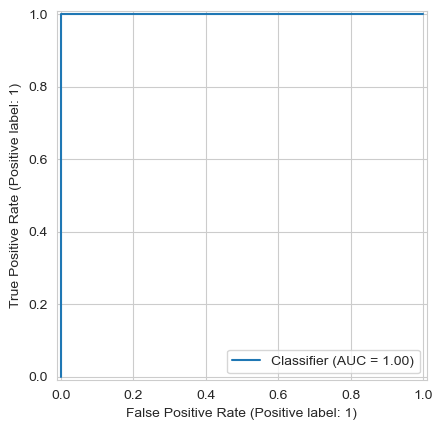

In [10]:
prob_train = model.predict_proba(Xtr_s[:, keep])[:, 1]
pred_train = model.predict(Xtr_s[:, keep])
print(confusion_matrix(y_train, pred_train))
print('train accuracy:', accuracy_score(y_train, pred_train))
print('train AUC:', roc_auc_score(y_train, prob_train))
RocCurveDisplay.from_predictions(y_train, prob_train)
plt.show()

The selected features, coefficients and p-values are in the table above (the p-values come from a binomial GLM in statsmodels). The model classifies all 69 training instances correctly, so the confusion matrix is diagonal and the AUC is 1. The p-values are all close to 1 and are not meaningful, because the classes are separable and the maximum likelihood estimates do not exist (see (vi)).

### (v) Test the classifier on the test set

In [11]:
prob_test = model.predict_proba(Xte_s[:, keep])[:, 1]
pred_test = model.predict(Xte_s[:, keep])
print(confusion_matrix(y_test, pred_test))
print('test accuracy:', accuracy_score(y_test, pred_test))
print('cross-validation accuracy:', round(cv_acc.loc[best_l, best_p], 4))
print('test AUC:', roc_auc_score(y_test, prob_test))

[[15  0]
 [ 0  4]]
test accuracy: 1.0
cross-validation accuracy: 0.9857
test AUC: 1.0


The test accuracy is 1.0 (15 other and 4 bending instances all correct), which is a little higher than the cross-validation accuracy of 0.9857. The two numbers are consistent. The test set only has 19 instances, so one mistake would move the accuracy by more than 5 percent.

### (vi) Are the classes well-separated?

In [12]:
print('train accuracy:', accuracy_score(y_train, pred_train))
print('largest |standardized coefficient|:', np.abs(model.coef_).max().round(2))
print('smallest p-value:', sm_fit.pvalues.min().round(4))

train accuracy: 1.0
largest |standardized coefficient|: 7.63
smallest p-value: 0.9987


Yes. The training accuracy is 1.0, so the classes are linearly separable in the selected features. When the classes are separable the likelihood keeps increasing as the coefficients grow, so the coefficients are very large even on standardized features, the standard errors are huge and every p-value is close to 1. The max_iter was limited to 100 to stop the optimization early. The classifier itself is still usable for prediction, but the coefficient estimates and the p-values are not reliable.

### (vii) Class imbalance and case-control sampling

bending: 9  other: 60
train confusion matrix:
[[59  1]
 [ 0  9]]
train accuracy: 0.9855072463768116  AUC: 1.0
test confusion matrix:
[[15  0]
 [ 1  3]]
test accuracy: 0.9473684210526315  AUC: 0.9666666666666667


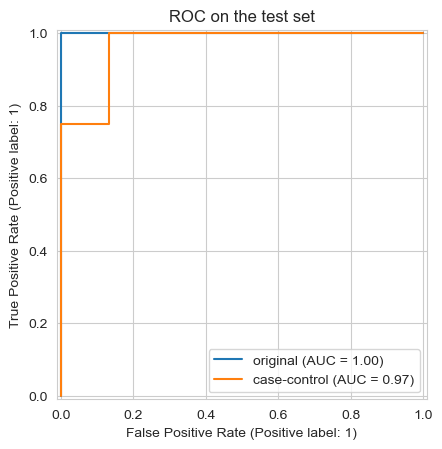

In [13]:
print('bending:', y_train.sum(), ' other:', (y_train == 0).sum())

rng = np.random.default_rng(0)
cases = np.where(y_train == 1)[0]
controls = rng.choice(np.where(y_train == 0)[0], size=len(cases), replace=False)
cc = np.r_[cases, controls]

cc_model = LogisticRegression(penalty=None, max_iter=100).fit(Xtr_s[cc][:, keep], y_train[cc])
pi = y_train.mean()
cc_model.intercept_ = cc_model.intercept_ + np.log(pi / (1 - pi)) - np.log(0.5 / 0.5)

for name, X_, y_ in [('train', Xtr_s, y_train), ('test', Xte_s, y_test)]:
    prob = cc_model.predict_proba(X_[:, keep])[:, 1]
    pred = cc_model.predict(X_[:, keep])
    print(name, 'confusion matrix:')
    print(confusion_matrix(y_, pred))
    print(name, 'accuracy:', accuracy_score(y_, pred), ' AUC:', roc_auc_score(y_, prob))

prob_cc = cc_model.predict_proba(Xte_s[:, keep])[:, 1]
RocCurveDisplay.from_predictions(y_test, prob_test, name='original')
plt.gca().set_title('ROC on the test set')
RocCurveDisplay.from_predictions(y_test, prob_cc, name='case-control', ax=plt.gca())
plt.show()

Yes, the classes are imbalanced: 9 bending and 60 other instances in the training set (about 13 percent bending). For case-control sampling all 9 bending instances and 9 randomly chosen other instances were used to fit the model, and the intercept was then corrected by log(pi / (1 - pi)), where pi = 9/69 is the proportion of bending in the training set. On the test set this model makes one mistake (a bending instance classified as other), accuracy 0.947 and AUC 0.967, which is slightly worse than the original model. With only 18 training instances this difference is not meaningful, and the original model is already accurate.

## (b) Binary classification using L1-penalized logistic regression

### (i) Choose l and lambda by cross-validation

In [14]:
Cs = np.logspace(-2, 2, 15)
l1_cv = {}
for l in range(1, 21):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='liblinear'))
    gs = GridSearchCV(pipe, {'logisticregression__C': Cs}, cv=skf, scoring='accuracy')
    gs.fit(X_by_l[l][train_idx], y_train)
    l1_cv[l] = (gs.best_score_, gs.best_params_['logisticregression__C'], gs.best_estimator_)

l1_table = pd.DataFrame({l: v[:2] for l, v in l1_cv.items()}, index=['cv accuracy', 'best C']).T
best_l1 = l1_table['cv accuracy'].idxmax()
l1_model = l1_cv[best_l1][2]
print('best l:', best_l1, ' best C:', l1_cv[best_l1][1], ' cv accuracy:', round(l1_cv[best_l1][0], 4))
l1_table.round(3)

best l: 1  best C: 0.517947467923121  cv accuracy: 0.9857


,cv accuracy,best C
1,0.986,0.518
2,0.971,13.895
3,0.971,0.268
4,0.927,0.518
5,0.927,0.268
6,0.942,7.197
7,0.942,26.827
8,0.927,0.268
9,0.942,0.518
10,0.956,51.795


non-zero coefficients: 4 of 42
[[15  0]
 [ 0  4]]
test accuracy: 1.0  test AUC: 1.0


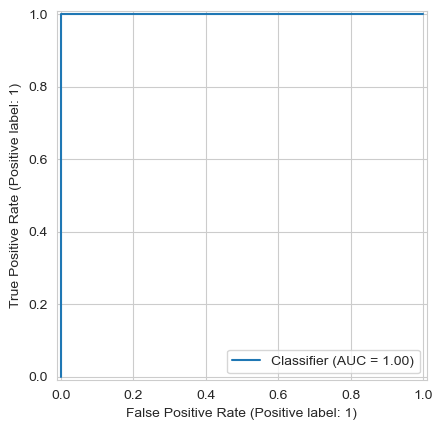

In [15]:
X_test_l1 = X_by_l[best_l1][is_test]
pred_l1 = l1_model.predict(X_test_l1)
prob_l1 = l1_model.predict_proba(X_test_l1)[:, 1]
print('non-zero coefficients:', (l1_model[-1].coef_ != 0).sum(), 'of', X_test_l1.shape[1])
print(confusion_matrix(y_test, pred_l1))
print('test accuracy:', accuracy_score(y_test, pred_l1), ' test AUC:', roc_auc_score(y_test, prob_l1))
RocCurveDisplay.from_predictions(y_test, prob_l1)
plt.show()

The best choice is l = 1 with C about 0.52 (lambda = 1/C) and a cross-validation accuracy of 0.9857. Only 4 of the 42 coefficients are non-zero. The test accuracy is 1.0 and the AUC is 1.

### (ii) Compare with the p-value based variable selection

Both approaches reach the same cross-validation accuracy (0.9857) and the same perfect result on the test set, so neither is better in accuracy. The L1-penalized model is easier to implement: one pipeline with cross-validation chooses l and lambda together, and the penalty does the variable selection. The p-value or RFE approach needs a separate elimination loop for every fold, and the p-values are not reliable here because of the separable classes. The L1 model is also more stable for the same reason.

## (c) Multi-class classification

### (i) L1-penalized multinomial logistic regression

In [16]:
classes = np.array(folders)
y_multi = np.array([folders.index(f) for f in activity])
ym_train, ym_test = y_multi[train_idx], y_multi[is_test]

Cs_m = [0.1, 0.3, 1, 3]
multi_cv = {}
for l in range(1, 21):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='saga', tol=1e-3, max_iter=500))
    gs = GridSearchCV(pipe, {'logisticregression__C': Cs_m}, cv=skf, scoring='accuracy', n_jobs=-1)
    gs.fit(X_by_l[l][train_idx], ym_train)
    multi_cv[l] = (gs.best_score_, gs.best_params_['logisticregression__C'], gs.best_estimator_)

multi_table = pd.DataFrame({l: v[:2] for l, v in multi_cv.items()}, index=['cv accuracy', 'best C']).T
best_lm = multi_table['cv accuracy'].idxmax()
multi_model = multi_cv[best_lm][2]
print('best l:', best_lm, ' best C:', multi_cv[best_lm][1], ' cv accuracy:', round(multi_cv[best_lm][0], 4))
multi_table.round(3)

best l: 1  best C: 3  cv accuracy: 0.9264


,cv accuracy,best C
1,0.926,3.0
2,0.868,1.0
3,0.825,1.0
4,0.797,3.0
5,0.840,3.0
6,0.824,1.0
7,0.781,3.0
8,0.796,1.0
9,0.780,0.3
10,0.809,3.0


test error: 0.1053


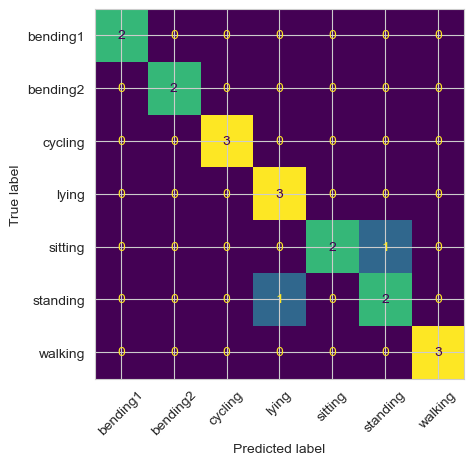

In [17]:
Xm_test = X_by_l[best_lm][is_test]
pred_m = multi_model.predict(Xm_test)
prob_m = multi_model.predict_proba(Xm_test)
print('test error:', round(1 - accuracy_score(ym_test, pred_m), 4))
ConfusionMatrixDisplay.from_predictions(ym_test, pred_m, display_labels=classes, xticks_rotation=45, colorbar=False)
plt.show()

For a multi-class problem the confusion matrix is a K x K table where entry (i, j) counts the instances of true class i predicted as class j. The ROC curve is defined one class at a time (one-vs-rest): class k is treated as the positive class and all other classes as negative, using the predicted probability of class k. This gives one curve and one AUC per class, and the macro-average AUC is the mean of them.

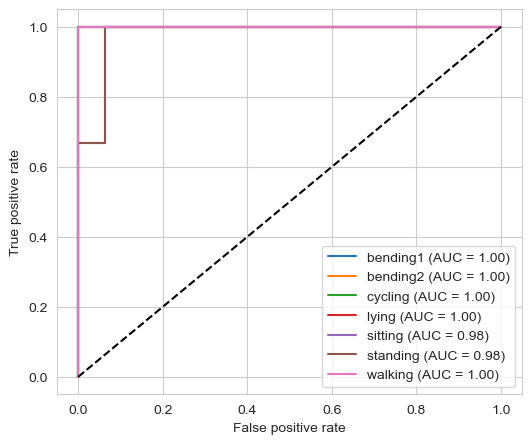

macro-average AUC: 0.9940476190476192


In [18]:
ym_bin = np.eye(len(classes))[ym_test]
plt.figure(figsize=(6, 5))
for k in range(len(classes)):
    if ym_bin[:, k].sum() == 0:
        continue
    fpr, tpr, _ = roc_curve(ym_bin[:, k], prob_m[:, k])
    plt.plot(fpr, tpr, label=f'{classes[k]} (AUC = {roc_auc_score(ym_bin[:, k], prob_m[:, k]):.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.show()
print('macro-average AUC:', roc_auc_score(ym_test, prob_m, multi_class='ovr', average='macro', labels=range(len(classes))))

The best choice is l = 1 with C = 3 and a cross-validation accuracy of 0.926. The test error is 0.105 (2 of 19 instances): one sitting instance is predicted as standing and one standing instance is predicted as lying, while the bending, cycling and walking instances are all correct. The macro-average one-vs-rest AUC is 0.994.

### (ii) Naive Bayes with Gaussian and Multinomial priors

In [19]:
nb_table = pd.DataFrame(index=range(1, 21), columns=['Gaussian', 'Multinomial'], dtype=float)
for l in range(1, 21):
    X = X_by_l[l][train_idx]
    nb_table.loc[l, 'Gaussian'] = cross_val_score(GaussianNB(), X, ym_train, cv=skf).mean()
    nb_table.loc[l, 'Multinomial'] = cross_val_score(MultinomialNB(), X, ym_train, cv=skf).mean()

nb_best = {'Gaussian': (GaussianNB, nb_table['Gaussian'].idxmax()), 'Multinomial': (MultinomialNB, nb_table['Multinomial'].idxmax())}
nb_preds = {}
for name, (cls, l) in nb_best.items():
    nb = cls().fit(X_by_l[l][train_idx], ym_train)
    nb_preds[name] = nb.predict(X_by_l[l][is_test])
    print(name, ' best l:', l, ' cv accuracy:', round(nb_table.loc[l, name], 4), ' test error:', round(1 - accuracy_score(ym_test, nb_preds[name]), 4))
nb_table.round(3)

Gaussian  best l: 1  cv accuracy: 0.8538  test error: 0.1053
Multinomial  best l: 1  cv accuracy: 0.8549  test error: 0.1053


,Gaussian,Multinomial
1,0.854,0.855
2,0.767,0.767
3,0.682,0.782
4,0.652,0.738
5,0.679,0.782
6,0.638,0.767
7,0.580,0.813
8,0.610,0.767
9,0.567,0.798
10,0.666,0.738


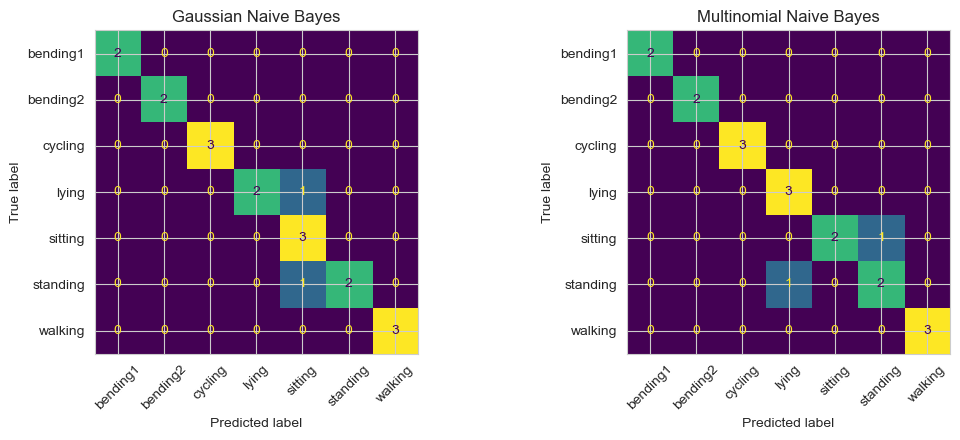

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, nb_preds):
    ConfusionMatrixDisplay.from_predictions(ym_test, nb_preds[name], display_labels=classes, xticks_rotation=45, colorbar=False, ax=ax)
    ax.set_title(name + ' Naive Bayes')
plt.tight_layout()
plt.show()

Both Naive Bayes models choose l = 1. The Gaussian model has a cross-validation accuracy of 0.854 and the multinomial model 0.855, and both have a test error of 0.105 (2 of 19), with the mistakes among lying, sitting and standing. Compared with the L1-penalized multinomial regression, the test error is the same, but the cross-validation accuracy is clearly lower (0.926 vs about 0.855). The accuracy of Naive Bayes also drops quickly when l grows, since the features are assumed to be independent.

### (iii) Which method is better for multi-class classification?

The L1-penalized multinomial logistic regression is better. It has the highest cross-validation accuracy (0.926 vs 0.854 and 0.855), the same test error as Naive Bayes, and it is less affected by large l because the penalty removes unneeded features. It also gives probabilities that are used for the ROC curves. The difference on the test set is small because it only contains 19 instances, so the cross-validation result is the better evidence.